# Dataset token distributions
Which characters and tokens are common? How much of each vocabulary is used?

**Start here:** select the TVA Python kernel, then Run All. Change only the settings below
to inspect another fold or Bigram, BPE, or Unigram.

- **IAM training text → ED:** compare English text with the same frozen tokenizers.
- **OnHW-Words500, right-handed:** show German character counts separately.
  German subword tokenizers wait for an approved German construction dataset (D026).

A character is one text symbol. A token can contain several characters:
"the" has three characters, but a tokenizer may emit "th" + "e".
This notebook counts labels only. It needs no checkpoint and trains nothing.

In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'main.py').is_file() and (p / 'tva').is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from collections import Counter
import csv
import hashlib
import json
import subprocess
from importlib.metadata import version
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from tva.ed_analysis import (DATA_ROOT, TOKENIZERS, iam_training_texts,
                             load_records, load_tokenizer, show_table)
from tva.compression_matched_tokenizers import IAM_EVIDENCE
from tva.handwriting_tokenizers import read_connectivity_lines

logger.disable('tva')

# ---- Settings ----
FAMILY = 'bigram'          # 'bigram', 'bpe', or 'unigram': detailed token charts
ED_SPLIT = 'wi'            # 'wd' or 'wi'
FOLD = 0                  # one fold at a time; do not add repeated folds together
TOP_N = 15
EXPORT = True
ONHW_ROOT = Path(os.environ.get('TVA_ONHW_DATA_ROOT', REPO_ROOT / 'data/tva')).expanduser()
OUTPUT_DIR = REPO_ROOT / 'results/dataset_token_distributions' / f'{ED_SPLIT}_fold{FOLD}_{FAMILY}'

assert FAMILY in {'bigram', 'bpe', 'unigram'}
assert ED_SPLIT in {'wd', 'wi'} and FOLD in range(5) and TOP_N > 0
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. What is counted?
Each source is divided by **its own total token count**. The charts show percentages,
so a larger dataset does not automatically have taller bars.

Case, spaces and punctuation are kept. Each line or recording counts once.
Repeated text in different recordings counts again. No folds or WD/WI copies are pooled.
The German charts describe the prepared OnHW population, after its existing filtering.

The character chart uses **all IAM training lines**. For English subword charts,
IAM lines containing symbols outside the ED alphabet are excluded, as in the existing
compression analysis. The excluded count is printed below. This is a descriptive
recording-level analysis; tokenizer training itself deduplicates text.

In [2]:
sources = []
def record_source(path, role):
    path = Path(path)
    payload = path.read_bytes()
    sources.append({'role': role, 'path': str(path.relative_to(REPO_ROOT)) if path.is_relative_to(REPO_ROOT)
                    else str(path), 'sha256': hashlib.sha256(payload).hexdigest()})
    return payload

record_source(IAM_EVIDENCE, 'IAM frozen training evidence')
if sources[-1]['sha256'] != '815304d2591bc187a2eea7dd76593499905c11645c8b9a146e7f1699c0e636fa':
    raise ValueError('IAM evidence checksum differs from artifacts/evidence/README.md')
iam_raw = [line['text'] for line in read_connectivity_lines(IAM_EVIDENCE)]
iam_compatible = iam_training_texts()

english_texts = {'IAM train (ED alphabet)': iam_compatible}
raw_texts = {'IAM train (all lines)': iam_raw}
ed_records = {}
for part, title in [('train', 'ED train'), ('val', 'ED validation')]:
    record_source(DATA_ROOT / f'gold_{ED_SPLIT}/{part}.json', title)
    ed_records[part] = load_records(ED_SPLIT, FOLD, part)
    english_texts[title] = [r['label'] for r in ed_records[part]]
    raw_texts[title] = english_texts[title]
if {r['id'] for r in ed_records['train']} & {r['id'] for r in ed_records['val']}:
    raise ValueError('ED sample IDs overlap between training and validation')
if ED_SPLIT == 'wi' and ({r['id_writer'] for r in ed_records['train']} &
                         {r['id_writer'] for r in ed_records['val']}):
    raise ValueError('ED WI writers overlap')

german_texts = {}
for setting in ('wd', 'wi'):
    writers = {}
    for part, title in [('train', 'train'), ('val', 'validation')]:
        name = f'OnHW {setting.upper()} {title}'
        path = ONHW_ROOT / f'onhw_words500_{setting}_word_rh/{part}.json'
        document = json.loads(record_source(path, name))
        if document['info']['writer_independent'] != (setting == 'wi'):
            raise ValueError(f'Wrong writer setting: {path}')
        records = document['annotations'][str(FOLD)]
        german_texts[name] = [r['label'] for r in records]
        if set(''.join(german_texts[name])) - set(document['categories']):
            raise ValueError(f'Unexpected OnHW characters: {path}')
        writers[part] = {r['id_writer'] for r in records}
    if setting == 'wi' and writers['train'] & writers['val']:
        raise ValueError('OnHW WI writers overlap')
raw_texts.update(german_texts)
for name, texts in {**raw_texts, **english_texts}.items():
    if not texts or any(not isinstance(t, str) or not t for t in texts):
        raise ValueError(f'Empty or invalid labels: {name}')

raw_counts = {name: Counter(''.join(texts)) for name, texts in raw_texts.items()}
show_table([{'Source': name, 'Labels': len(texts), 'Characters': sum(map(len, texts))}
            for name, texts in raw_texts.items()])
print(f'English token charts: {len(iam_compatible):,} of {len(iam_raw):,} IAM lines; '
      f'{len(iam_raw) - len(iam_compatible):,} excluded (outside ED alphabet).')
print(f'ED: {ED_SPLIT.upper()}, fold {FOLD}. OnHW: WD and WI, fold {FOLD}.')

English token charts: 5,612 of 5,694 IAM lines; 82 excluded (outside ED alphabet).
ED: WI, fold 0. OnHW: WD and WI, fold 0.


| Source | Labels | Characters |
| --- | --- | --- |
| IAM train (all lines) | 5694 | 241876 |
| ED train | 2025 | 84158 |
| ED validation | 525 | 21929 |
| OnHW WD train | 20163 | 108549 |
| OnHW WD validation | 5036 | 28527 |
| OnHW WI train | 19907 | 108199 |
| OnHW WI validation | 5292 | 28877 |

## 2. Which characters are common?
The English panel uses the same character order for IAM and ED.
The German panel compares OnHW training and validation in WD and WI.
"space" means a literal space; uppercase and lowercase letters remain separate.

Only the most common characters are drawn. Exact exports include every character.
Similar bars show similar character balance. They do not prove equal recognition difficulty.

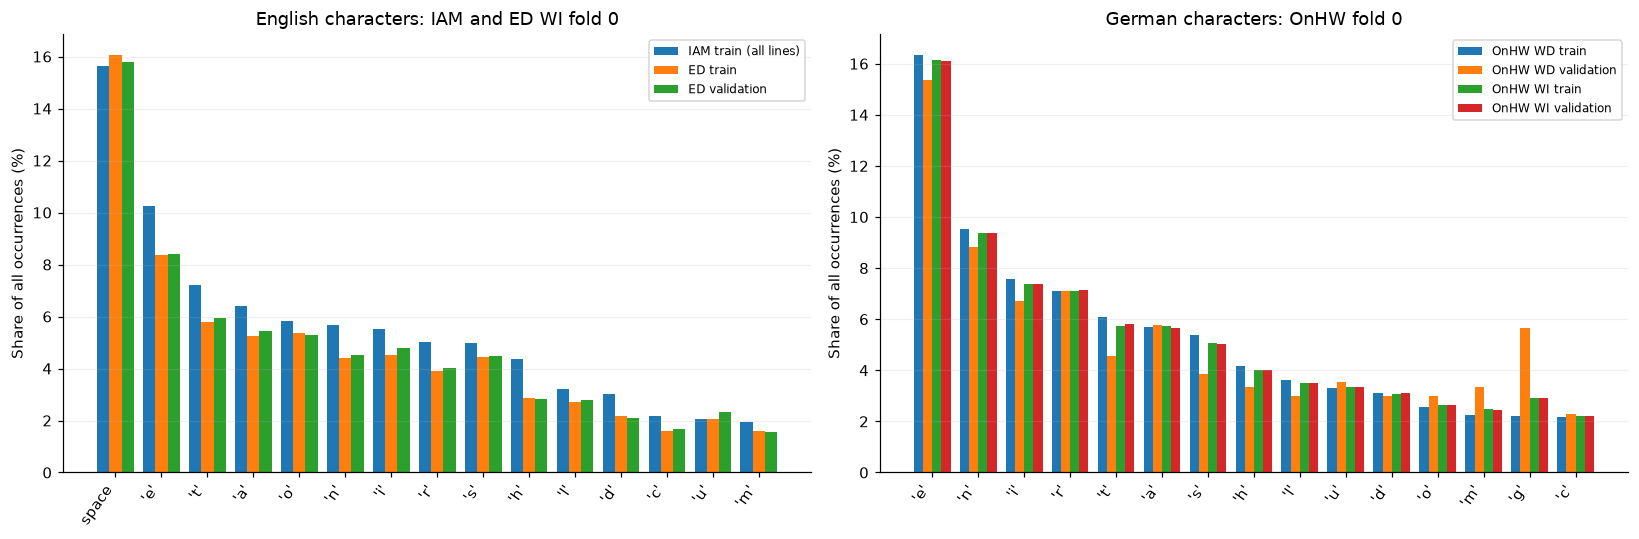

In [3]:
def visible(token):
    return 'space' if token == ' ' else repr(token)

def top_bars(ax, counts, title):
    # Select/order on IAM train or OnHW WD train, never on validation.
    first = next(iter(counts.values()))
    top = [t for t, _ in sorted(first.items(), key=lambda item: (-item[1], item[0]))[:TOP_N]]
    x = np.arange(len(top))
    width = 0.8 / len(counts)
    for i, (name, count) in enumerate(counts.items()):
        ax.bar(x + (i - (len(counts) - 1) / 2) * width,
               [100 * count[t] / sum(count.values()) for t in top], width, label=name)
    ax.set_xticks(x, [visible(t) for t in top], rotation=55, ha='right')
    ax.set_ylabel('Share of all occurrences (%)')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.2)

def finish_figure(fig, filename, rect=None):
    fig.tight_layout(rect=rect)
    if EXPORT:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=180, bbox_inches='tight')
        fig.savefig(OUTPUT_DIR / f'{filename}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_bars(axes[0], {name: raw_counts[name] for name in list(raw_texts)[:3]},
         f'English characters: IAM and ED {ED_SPLIT.upper()} fold {FOLD}')
top_bars(axes[1], {name: raw_counts[name] for name in german_texts},
         f'German characters: OnHW fold {FOLD}')
finish_figure(fig, '01_characters')

## 3. Which English tokens are common?
Both English datasets use **exactly the same frozen tokenizer** in each panel.
Text-only tokenizers learn from text alone. Handwriting-aware tokenizers also use
approved connected-letter pairs. **HW** means handwriting-aware. Bigram encoding is greedy on both sides (D024/D025).

Below, the left charts show common emitted tokens for the selected family.
The right charts show cumulative coverage: how many token occurrences are covered as we add
tokens from most to least frequent. A steep rise means a few tokens dominate.
Each source has its own frequency ranking for the coverage curve.

All counts exclude the CTC blank (the model's no-character output).
Validation counts describe the frozen vocabulary; they must not be used to change it.

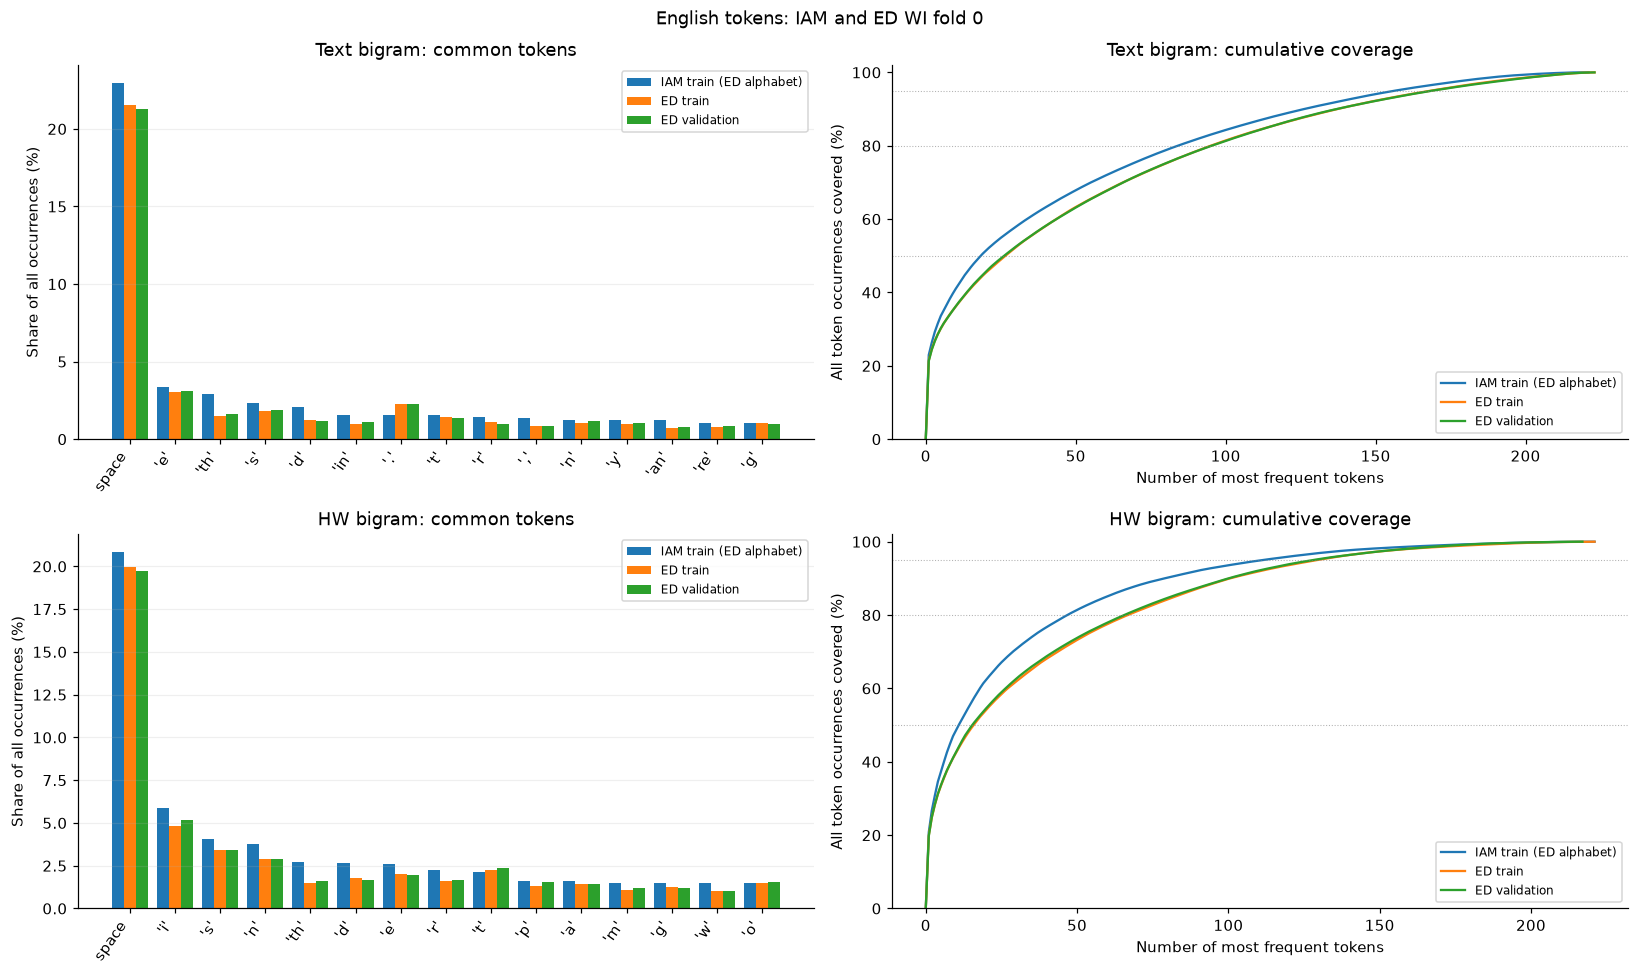

In [4]:
CONDITIONS = {
    'linguistic_bigram_letters': 'Text bigram', 'handwriting_bigram': 'HW bigram',
    'linguistic_bpe': 'Text BPE', 'handwriting_bpe': 'HW BPE',
    'linguistic_unigram': 'Text Unigram', 'handwriting_unigram': 'HW Unigram',
}
tokenizers = {condition: load_tokenizer(condition) for condition in CONDITIONS}
token_counts_by_condition = {}
vocabularies = {}
for condition, tokenizer in tokenizers.items():
    record_source(REPO_ROOT / TOKENIZERS[condition][1], condition)
    # Decode each ID once; count IDs actually emitted by the frozen encoder.
    vocab = {i: tokenizer.decode([i]) for i in range(1, tokenizer.size)}
    if len(set(vocab.values())) != len(vocab) or any(not t for t in vocab.values()):
        raise ValueError(f'Unexpected nonblank vocabulary: {condition}')
    vocabularies[condition] = vocab
    token_counts_by_condition[condition] = {}
    for name, texts in english_texts.items():
        ids = Counter()
        for text in texts:
            encoded = tokenizer.encode(text)
            if not encoded or 0 in encoded or tokenizer.decode(encoded) != text:
                raise ValueError(f'Encoding does not preserve the label: {condition}, {name}')
            ids.update(encoded)
        if set(ids) - set(vocab):
            raise ValueError(f'Out-of-range token IDs: {condition}')
        count = Counter({vocab[i]: ids[i] for i in vocab})
        assert sum(len(t) * n for t, n in count.items()) == sum(map(len, texts))
        token_counts_by_condition[condition][name] = count

selected = [('linguistic_bigram_letters' if FAMILY == 'bigram' else f'linguistic_{FAMILY}'),
            f'handwriting_{FAMILY}']
def ranked_counts(count):
    return np.array(sorted((n for n in count.values() if n > 0), reverse=True))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle(f'English tokens: IAM and ED {ED_SPLIT.upper()} fold {FOLD}')
for row, condition in enumerate(selected):
    counts = token_counts_by_condition[condition]
    top_bars(axes[row, 0], counts, CONDITIONS[condition] + ': common tokens')
    ax = axes[row, 1]
    for name, count in counts.items():
        values = ranked_counts(count)
        ax.plot(np.arange(len(values) + 1), np.r_[0, 100 * np.cumsum(values) / values.sum()],
                label=name)
    for level in (50, 80, 95):
        ax.axhline(level, color='grey', linewidth=0.7, linestyle=':', alpha=0.6)
    ax.set(xlabel='Number of most frequent tokens', ylabel='All token occurrences covered (%)',
           ylim=(0, 102), title=CONDITIONS[condition] + ': cumulative coverage')
    ax.legend(fontsize=8)
finish_figure(fig, '02_tokens_and_coverage')

## 4. Are many tokens rare?
Each curve sorts its own tokens from common to rare. Both axes use logarithmic
spacing so the rare end stays visible. Zero-count tokens are omitted here and
included in the vocabulary-use summary below.

A long low tail means many tokens occur only rarely.
Token rank is a position, not a shared token identity across curves.

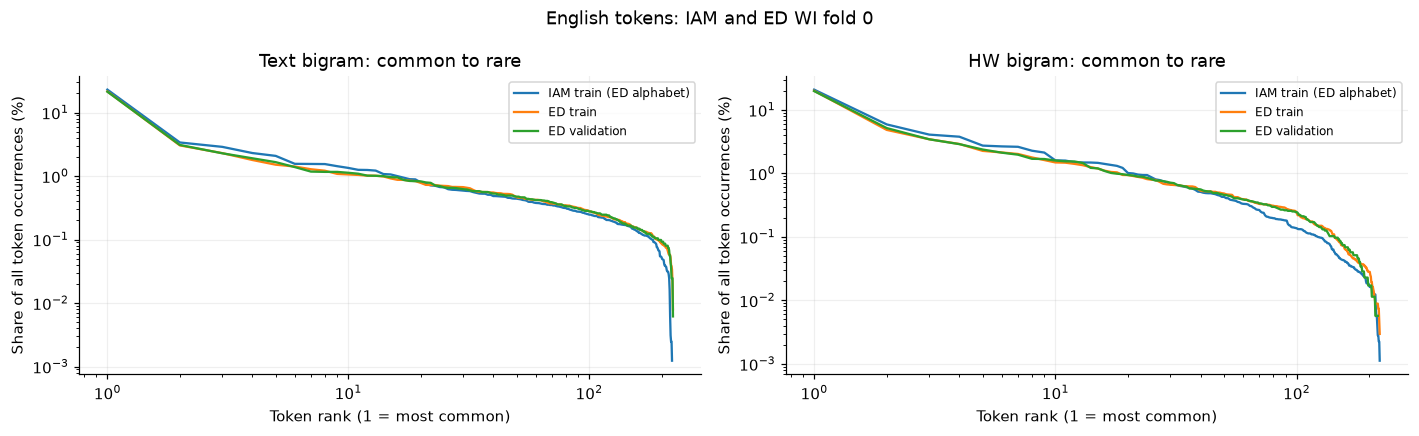

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'English tokens: IAM and ED {ED_SPLIT.upper()} fold {FOLD}')
for ax, condition in zip(axes, selected):
    for name, count in token_counts_by_condition[condition].items():
        values = ranked_counts(count)
        ax.loglog(np.arange(1, len(values) + 1), 100 * values / values.sum(), label=name)
    ax.set(xlabel='Token rank (1 = most common)', ylabel='Share of all token occurrences (%)',
           title=CONDITIONS[condition] + ': common to rare')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
finish_figure(fig, '03_common_to_rare')

## 5. How much does each tokenizer merge?
**Characters per token:** 1 means character-by-character text; higher means more merging.

**Learned pieces used:** the percentage of the 145 multi-character vocabulary entries
that occur at least once. Single-character fallbacks and the blank are excluded from
this percentage. A used piece can still be very rare.

These charts cover all three families. Counts and tokens per label are in the
exported summary table. IAM contains lines, ED contains sentences, and OnHW contains
words. Their sequence lengths are therefore not direct measures of task difficulty.

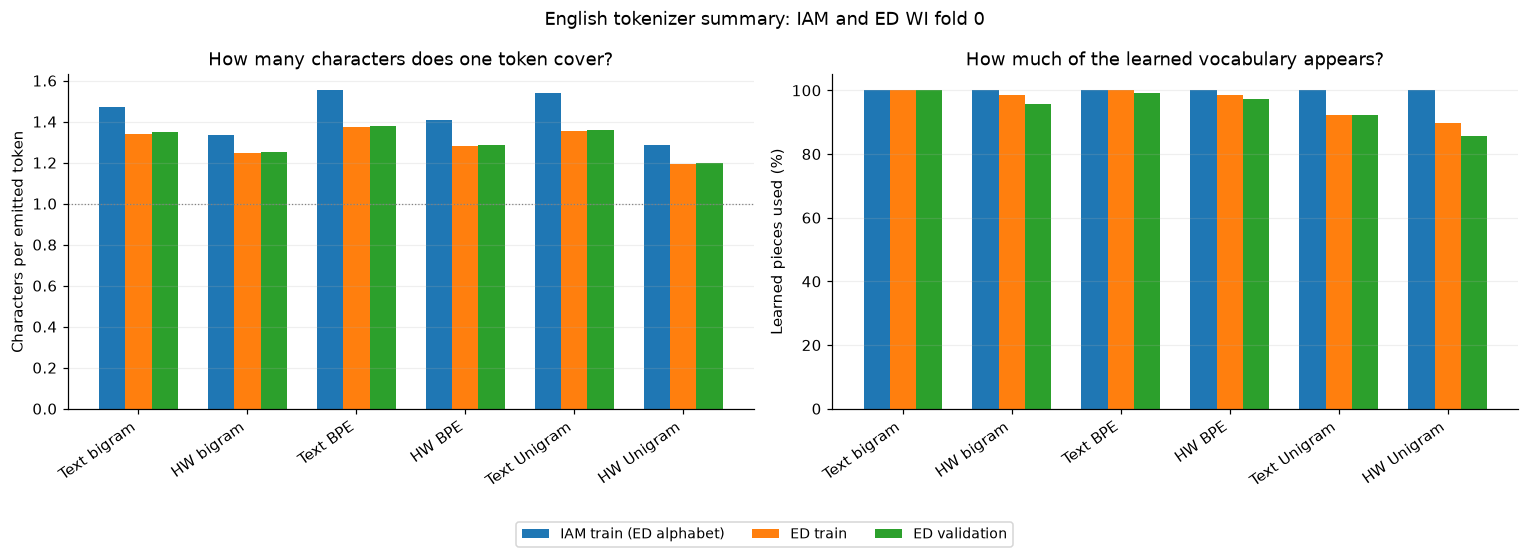

In [6]:
def coverage_size(count, fraction):
    values = ranked_counts(count)
    return int(np.searchsorted(np.cumsum(values), fraction * values.sum()) + 1)

summary = []
for condition, counts in token_counts_by_condition.items():
    learned = [t for t in vocabularies[condition].values() if len(t) > 1]
    assert len(learned) == 145
    for name, count in counts.items():
        total = sum(count.values())
        summary.append({
            'tokenizer': condition, 'source': name, 'labels': len(english_texts[name]),
            'tokens': total, 'tokens_per_label': total / len(english_texts[name]),
            'characters_per_token': sum(map(len, english_texts[name])) / total,
            'used_tokens': sum(n > 0 for n in count.values()),
            'unused_tokens': sum(n == 0 for n in count.values()),
            'learned_pieces': len(learned),
            'learned_pieces_used': sum(count[t] > 0 for t in learned),
            'learned_piece_occurrences_pct': 100 * sum(count[t] for t in learned) / total,
            **{f'tokens_for_{level}pct': coverage_size(count, level / 100) for level in (50, 80, 95)},
        })

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'English tokenizer summary: IAM and ED {ED_SPLIT.upper()} fold {FOLD}')
x = np.arange(len(CONDITIONS))
width = 0.24
for i, name in enumerate(english_texts):
    rows = [r for r in summary if r['source'] == name]
    axes[0].bar(x + (i - 1) * width, [r['characters_per_token'] for r in rows], width, label=name)
    axes[1].bar(x + (i - 1) * width,
                [100 * r['learned_pieces_used'] / r['learned_pieces'] for r in rows], width, label=name)
for ax in axes:
    ax.set_xticks(x, list(CONDITIONS.values()), rotation=35, ha='right')
    ax.grid(axis='y', alpha=0.2)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9)
axes[0].axhline(1, color='grey', linewidth=0.8, linestyle=':')
axes[0].set(title='How many characters does one token cover?', ylabel='Characters per emitted token', ylim=(0, None))
axes[1].set(title='How much of the learned vocabulary appears?', ylabel='Learned pieces used (%)', ylim=(0, 105))
finish_figure(fig, '04_tokenizer_summary', rect=(0, 0.08, 1, 1))

## 6. Save the figures and exact counts
With EXPORT=True, this run saves four PNG/PDF figure pairs, character and token
count tables, a tokenizer summary, and input checksums under the folder printed below.
Re-running the same settings refreshes only that analysis folder.
Set EXPORT=False to view charts without writing exports.

Missing inputs stop the notebook with an error. No dataset is silently dropped.
No model is run. These figures describe text distributions; they do not show that
one tokenizer improves recognition. German subword analysis remains pending.

In [7]:
if EXPORT:
    def write_csv(filename, rows):
        with (OUTPUT_DIR / filename).open('w', encoding='utf-8', newline='') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

    all_characters = sorted({char for count in raw_counts.values() for char in count})
    write_csv('character_counts.csv', [
        {'source': name, 'character': char, 'count': count[char],
         'frequency_pct': 100 * count[char] / sum(count.values())}
        for name, count in raw_counts.items() for char in all_characters
    ])
    write_csv('token_counts.csv', [
        {'tokenizer': condition, 'source': name, 'token_id': token_id,
         'token': token, 'count': counts[name][token],
         'frequency_pct': 100 * counts[name][token] / sum(counts[name].values())}
        for condition, counts in token_counts_by_condition.items()
        for name in english_texts for token_id, token in vocabularies[condition].items()
    ])
    write_csv('tokenizer_summary.csv', summary)

    def git_output(*args):
        result = subprocess.run(['git', *args], cwd=REPO_ROOT, capture_output=True, text=True)
        if result.returncode:
            raise RuntimeError(result.stderr)
        return result.stdout.strip()

    report = {
        'created_utc': datetime.now(timezone.utc).isoformat(),
        'git_revision': git_output('rev-parse', 'HEAD'),
        'git_status': git_output('status', '--short', '--untracked-files=normal'),
        'python': sys.version, 'python_executable': sys.executable,
        'packages': {name: version(name) for name in ('numpy', 'matplotlib', 'tokenizers')},
        'notebook_source_sha256': hashlib.sha256('\n\n'.join(
            ''.join(cell['source']) for cell in json.loads((REPO_ROOT /
            'notebooks/analysis/compare_dataset_token_distributions.ipynb').read_text())['cells']
        ).encode('utf-8')).hexdigest(),
        'settings': {'family': FAMILY, 'ed_split': ED_SPLIT, 'fold': FOLD, 'top_n': TOP_N},
        'counting': 'Per line/recording, repeats retained, case/spaces/punctuation retained; no fold pooling; blank excluded',
        'iam_lines_all': len(iam_raw), 'iam_lines_for_tokens': len(iam_compatible),
        'iam_lines_excluded_from_tokens': len(iam_raw) - len(iam_compatible),
        'iam_token_filter': 'Whole lines with characters outside ED_ALPHABET are excluded, matching iam_training_texts()',
        'onhw': 'Prepared right-handed data; character analysis only',
        'sources': sources, 'summary': summary,
    }
    (OUTPUT_DIR / 'report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    print('Saved charts and tables:', OUTPUT_DIR.relative_to(REPO_ROOT))
else:
    print('Charts displayed; exports disabled.')

Saved charts and tables: results/dataset_token_distributions/wi_fold0_bigram
